# Community Detection for Social Media Data
### Louvain vs. Clique Percolation (CPM) vs. Label Propagation, applied to a brand-marketing use case

**Business use case:** *NovaFit*, a fitness-wearable brand, wants to understand the conversation around its products on social media. Instead of treating followers as one blob, we **discover natural communities** in the user interaction network (mentions / retweets / replies) and then use them to:

1. **Segment the audience** into interest groups (who talks to whom).
2. **Pick influencers** per community for seeding campaigns.
3. **Find bridge users** who connect communities (good for cross-promotion).
4. **Tailor messaging** per community (sentiment, engagement, hashtags).

**Algorithms**
| Algorithm | Type | Idea |
|---|---|---|
| Louvain | Non-overlapping, modularity-based | Greedily maximises modularity, then collapses communities into super-nodes and repeats |
| Clique Percolation (CPM) | **Overlapping**, structure-based | A community is a union of adjacent *k*-cliques (sharing *k-1* nodes) |
| Label Propagation | Non-overlapping, fast baseline | Each node adopts the majority label of its neighbours |

**Notebook outline:** data → EDA → Louvain → Clique Percolation → comparison → visualisation → community profiling → influencers & bridges → campaign simulation → real-data option → conclusions.

## 1. Setup

In [ ]:
import time, warnings, collections
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics import normalized_mutual_info_score as NMI, adjusted_rand_score as ARI

warnings.filterwarnings("ignore")
SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

print("networkx", nx.__version__)   # needs >= 2.8 for nx.community.louvain_communities

networkx 3.7


## 2. Data: a synthetic social-media interaction network

To keep the notebook self-contained and reproducible, we simulate **NovaFit's** audience. Users belong to 6 latent interest segments (the *ground truth*, which lets us measure how well each algorithm recovers them, something you can't do on real data). Edges are interactions (mention / retweet / reply) weighted by interaction count. A few **bridge users** are wired into two segments to create overlapping membership.

Each user also has attributes (followers, engagement rate, brand sentiment, hashtags) that we use later for profiling. A real-data option (SNAP Facebook) is at the end.

In [ ]:
SEGMENTS = {
    "Runners":        ["#running", "#marathon", "#5k", "#trailrun", "#pace"],
    "Strength":       ["#gym", "#lifting", "#gains", "#crossfit", "#protein"],
    "Yoga/Wellness":  ["#yoga", "#mindfulness", "#sleep", "#wellness", "#selfcare"],
    "Tech Reviewers": ["#wearables", "#gadgets", "#review", "#smartwatch", "#battery"],
    "Deal Hunters":   ["#deals", "#discount", "#blackfriday", "#coupon", "#budget"],
    "Parents":        ["#parenting", "#familyfitness", "#momlife", "#kids", "#schoolrun"],
}
GLOBAL_TAGS = ["#fitness", "#health", "#novafit", "#motivation", "#steps"]
seg_names = list(SEGMENTS)
sizes = [60, 52, 46, 42, 36, 30]
K = len(sizes)

# block connection probabilities: dense inside, sparse outside, a few "neighbouring" segments
P = np.full((K, K), 0.008)
np.fill_diagonal(P, [0.30, 0.26, 0.28, 0.24, 0.25, 0.30])
for a, b in [(0, 1), (2, 5), (3, 4)]:
    P[a, b] = P[b, a] = 0.02

G = nx.stochastic_block_model(sizes, P, seed=SEED)
truth = {n: b for b, blk in enumerate(G.graph["partition"]) for n in blk}
blocks = [sorted(blk) for blk in G.graph["partition"]]

# --- bridge users: join a second segment through a tight group of its members
bridge_nodes = rng.choice(G.number_of_nodes(), size=14, replace=False)
for u in bridge_nodes:
    other = rng.choice([b for b in range(K) if b != truth[u]])
    anchor = rng.choice(blocks[other])
    pool = [anchor] + list(G.neighbors(anchor))
    pool = [v for v in pool if truth[v] == other and v != u]
    for v in rng.choice(pool, size=min(6, len(pool)), replace=False):
        G.add_edge(int(u), int(v))

# --- edge weights = interaction counts (stronger inside a segment)
for u, v in G.edges():
    lam = 3 if truth[u] == truth[v] else 1
    G[u][v]["weight"] = int(rng.poisson(lam)) + 1

# --- user attributes
sent_mean = [0.50, 0.30, 0.60, 0.00, -0.15, 0.20]
eng_mean  = [4.5, 3.8, 3.2, 2.5, 1.8, 3.0]          # engagement-rate % by segment
rows = []
for n in G.nodes():
    s = truth[n]
    tags = [rng.choice(SEGMENTS[seg_names[s]]) if rng.random() < 0.7 else rng.choice(GLOBAL_TAGS) for _ in range(3)]
    rows.append(dict(user=n,
                     followers=int(rng.lognormal(6.0, 1.2)),
                     engagement_pct=float(np.clip(rng.normal(eng_mean[s], 1.0), 0.2, 12)),
                     sentiment=float(np.clip(rng.normal(sent_mean[s], 0.3), -1, 1)),
                     hashtags=" ".join(tags),
                     true_segment=seg_names[s]))
users = pd.DataFrame(rows).set_index("user")
nodes = list(G.nodes())
true_labels = [truth[n] for n in nodes]

print(f"{G.number_of_nodes()} users, {G.number_of_edges()} interaction edges")
users.head()

266 users, 2107 interaction edges


,followers,engagement_pct,sentiment,hashtags,true_segment
user,,,,,
0,118,4.680863,-0.212133,#trailrun #running #pace,Runners
1,251,4.838272,0.639587,#novafit #marathon #5k,Runners
2,315,3.238425,-0.054361,#pace #marathon #health,Runners
3,47,5.436113,-0.151659,#5k #novafit #trailrun,Runners
4,168,2.662039,0.259672,#pace #running #5k,Runners


## 3. Exploratory network analysis

Nodes: 266 | Edges: 2107 | Density: 0.0598
Avg degree: 15.8 | Max degree: 36 | Isolated: 0
Connected components: 1
Avg clustering coefficient: 0.204


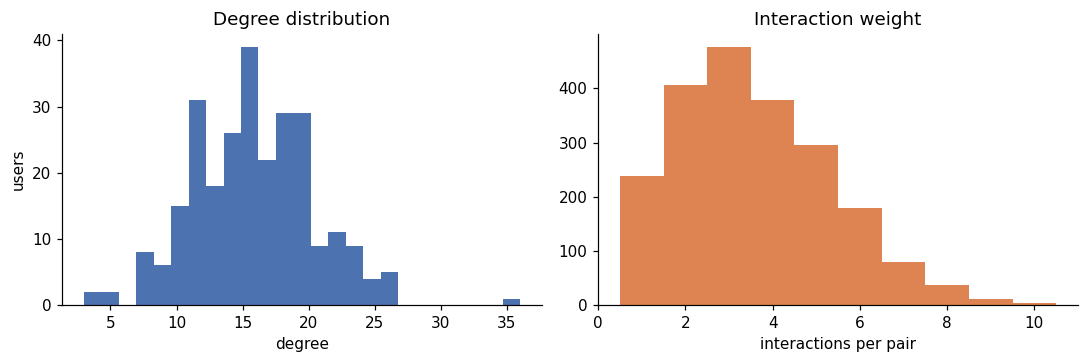

In [ ]:
deg = np.array([d for _, d in G.degree()])
print(f"Nodes: {G.number_of_nodes()} | Edges: {G.number_of_edges()} | Density: {nx.density(G):.4f}")
print(f"Avg degree: {deg.mean():.1f} | Max degree: {deg.max()} | Isolated: {nx.number_of_isolates(G)}")
print(f"Connected components: {nx.number_connected_components(G)}")
print(f"Avg clustering coefficient: {nx.average_clustering(G):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(deg, bins=25, color="#4c72b0"); ax[0].set(title="Degree distribution", xlabel="degree", ylabel="users")
w = [d["weight"] for _, _, d in G.edges(data=True)]
ax[1].hist(w, bins=range(1, max(w) + 2), color="#dd8452", align="left"); ax[1].set(title="Interaction weight", xlabel="interactions per pair")
plt.tight_layout(); plt.show()

## 4. Evaluation helpers

* **Modularity** (Q): how much denser the communities are than a random graph with the same degrees. For CPM (overlapping) we compute Q on a *hard* version: overlapping nodes go to their first community, uncovered nodes become singletons.
* **NMI / ARI**: agreement with the ground-truth segments (1 = perfect). For CPM they are computed only on nodes covered by some community.
* **Coverage**: share of users that belong to at least one community.

In [ ]:
def hard_partition(communities, graph):
    """Convert (possibly overlapping / partial) communities to a proper partition."""
    seen, part = set(), []
    for c in communities:
        c = set(c) - seen
        if c:
            part.append(c); seen |= c
    part += [{n} for n in graph.nodes() if n not in seen]   # uncovered -> singletons
    return part

def to_labels(communities, node_list):
    lab = {}
    for i, c in enumerate(communities):
        for n in c:
            lab.setdefault(n, i)                            # first community wins
    return np.array([lab.get(n, -1) for n in node_list])

def evaluate(name, communities, graph, runtime=None):
    comms = [set(c) for c in communities]
    lab = to_labels(comms, nodes)
    covered = lab >= 0
    truth_arr = np.array(true_labels)
    Q = nx.community.modularity(graph, hard_partition(comms, graph), weight="weight")
    sizes_ = sorted((len(c) for c in comms), reverse=True)
    n_overlap = sum(1 for n in nodes if sum(n in c for c in comms) > 1)
    return dict(algorithm=name, communities=len(comms), coverage=covered.mean(),
                overlapping_nodes=n_overlap, modularity=Q,
                NMI=NMI(truth_arr[covered], lab[covered]) if covered.any() else np.nan,
                ARI=ARI(truth_arr[covered], lab[covered]) if covered.any() else np.nan,
                largest=sizes_[0] if sizes_ else 0, runtime_s=runtime)

## 5. Louvain method

Louvain has a **resolution** parameter: low values give fewer, larger communities; high values give many small ones. We sweep it and pick the setting with the best modularity (in practice you would also sanity-check against business interpretability).

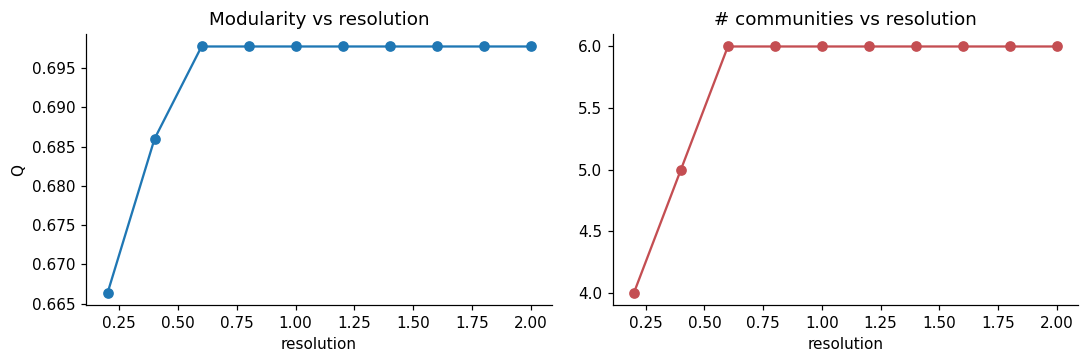

,resolution,communities,modularity,NMI
0,0.2,4,0.666,0.874
1,0.4,5,0.686,0.939
2,0.6,6,0.698,1.000
3,0.8,6,0.698,1.000
4,1.0,6,0.698,1.000
5,1.2,6,0.698,1.000
6,1.4,6,0.698,1.000
7,1.6,6,0.698,1.000
8,1.8,6,0.698,1.000
9,2.0,6,0.698,1.000


Best resolution by modularity: 0.6
Louvain found 6 communities in 0.057s


In [ ]:
res_grid = np.round(np.arange(0.2, 2.01, 0.2), 1)
sweep = []
for r in res_grid:
    comms = nx.community.louvain_communities(G, weight="weight", resolution=float(r), seed=SEED)
    m = evaluate(f"Louvain r={r}", comms, G)
    sweep.append(dict(resolution=r, communities=m["communities"], modularity=m["modularity"], NMI=m["NMI"]))
sweep = pd.DataFrame(sweep)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(sweep.resolution, sweep.modularity, "o-"); ax[0].set(title="Modularity vs resolution", xlabel="resolution", ylabel="Q")
ax[1].plot(sweep.resolution, sweep.communities, "o-", color="#c44e52"); ax[1].set(title="# communities vs resolution", xlabel="resolution")
plt.tight_layout(); plt.show()
display(sweep.round(3))

best_res = float(sweep.loc[sweep.modularity.idxmax(), "resolution"])
print("Best resolution by modularity:", best_res)

t0 = time.perf_counter()
louvain_comms = nx.community.louvain_communities(G, weight="weight", resolution=best_res, seed=SEED)
t_louvain = time.perf_counter() - t0
print(f"Louvain found {len(louvain_comms)} communities in {t_louvain:.3f}s")

## 6. Clique Percolation Method (CPM)

CPM finds **overlapping** communities: a user can belong to several (e.g. a runner who is also a gadget reviewer). The parameter *k* is the clique size: small *k* gives big, loose communities; large *k* gives small, tight ones and leaves many users uncovered.

In [ ]:
cpm_results = {}
for k in [3, 4, 5, 6]:
    t0 = time.perf_counter()
    comms = [set(c) for c in nx.community.k_clique_communities(G, k)]
    cpm_results[k] = (comms, time.perf_counter() - t0)

cpm_table = pd.DataFrame([evaluate(f"CPM k={k}", c, G, t) for k, (c, t) in cpm_results.items()])
display(cpm_table.round(3))

,algorithm,communities,coverage,overlapping_nodes,modularity,NMI,ARI,largest,runtime_s
0,CPM k=3,3,1.000,6,0.000,0.000,0.000,266,0.253
1,CPM k=4,49,0.906,109,0.459,0.775,0.758,61,0.044
2,CPM k=5,16,0.259,19,0.056,0.634,0.231,8,0.016
3,CPM k=6,0,0.000,0,-0.004,NaN,NaN,0,0.013


In [ ]:
# Choose k: prefer the setting with high coverage AND high NMI on the covered nodes
cpm_table["score"] = cpm_table.coverage * cpm_table.NMI.fillna(0)
best_k = int(cpm_table.loc[cpm_table.score.idxmax(), "algorithm"].split("=")[1])
cpm_comms, t_cpm = cpm_results[best_k]
print(f"Selected k = {best_k} -> {len(cpm_comms)} communities")

membership = collections.Counter(n for c in cpm_comms for n in c)
overlap_nodes = sorted(n for n, m in membership.items() if m > 1)
print(f"{len(overlap_nodes)} users belong to more than one community")
print("Uncovered users:", G.number_of_nodes() - len(membership))
print("Planted bridge users recovered as overlapping:", len(set(overlap_nodes) & set(map(int, bridge_nodes))), "/", len(bridge_nodes))

Selected k = 4 -> 49 communities
109 users belong to more than one community
Uncovered users: 25
Planted bridge users recovered as overlapping: 9 / 14


## 7. Baseline (Label Propagation) and head-to-head comparison

,communities,coverage,overlapping_nodes,modularity,NMI,ARI,largest,runtime_s
algorithm,,,,,,,,
Louvain (r=0.6),6,1.000,0,0.698,1.000,1.000,60,0.057
Clique Percolation (k=4),49,0.906,109,0.459,0.775,0.758,61,0.044
Label Propagation,6,1.000,0,0.698,1.000,1.000,60,0.044


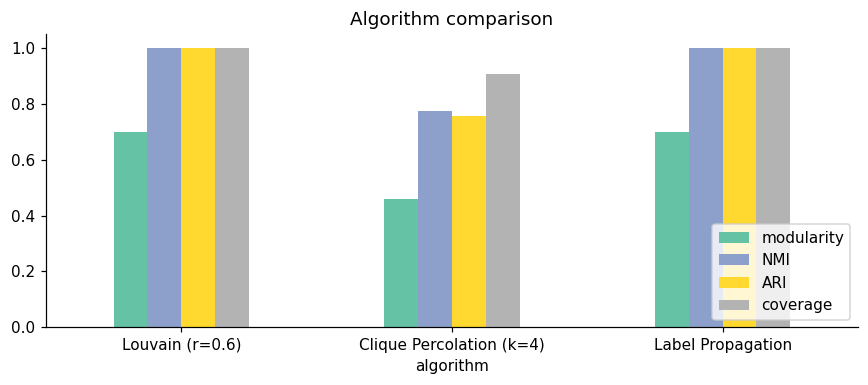

In [ ]:
t0 = time.perf_counter()
lpa_comms = list(nx.community.asyn_lpa_communities(G, weight="weight", seed=SEED))
t_lpa = time.perf_counter() - t0

comparison = pd.DataFrame([
    evaluate(f"Louvain (r={best_res})", louvain_comms, G, t_louvain),
    evaluate(f"Clique Percolation (k={best_k})", cpm_comms, G, t_cpm),
    evaluate("Label Propagation", lpa_comms, G, t_lpa),
]).set_index("algorithm")
display(comparison.round(3))

comparison[["modularity", "NMI", "ARI", "coverage"]].plot(kind="bar", figsize=(8, 3.6), rot=0, colormap="Set2")
plt.title("Algorithm comparison"); plt.ylim(0, 1.05); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

## 8. Visualising the communities

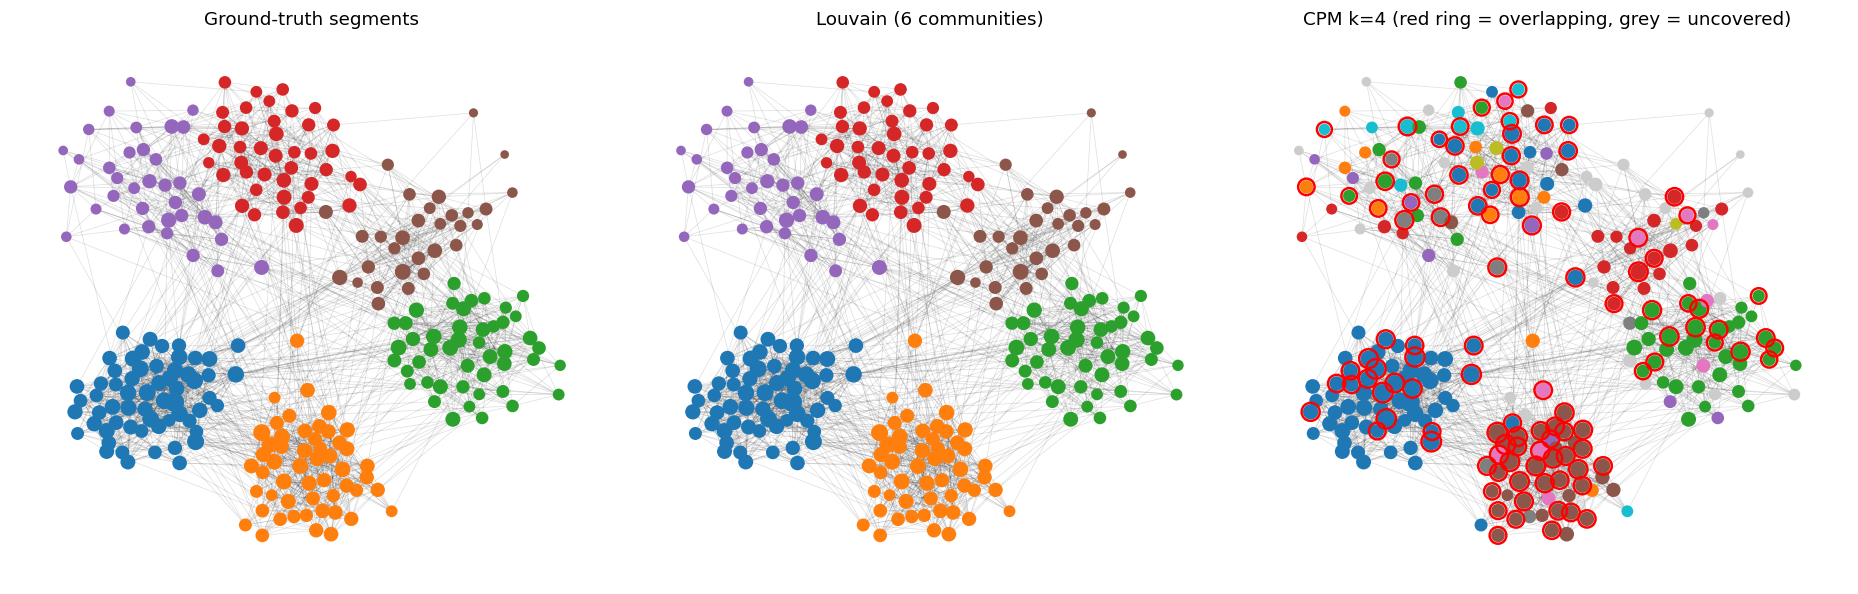

In [ ]:
pos = nx.spring_layout(G, weight="weight", k=0.35, iterations=200, seed=SEED)
palette = plt.cm.tab10.colors

def draw(ax, labels, title, highlight=None):
    cols = [palette[l % 10] if l >= 0 else "#cccccc" for l in labels]
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.12, width=0.5)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=cols, node_size=[20 + 4 * G.degree(n) for n in nodes], linewidths=0)
    if highlight:
        nx.draw_networkx_nodes(G, pos, nodelist=highlight, ax=ax, node_color="none", edgecolors="red",
                               node_size=[60 + 4 * G.degree(n) for n in highlight], linewidths=1.6)
    ax.set_title(title); ax.axis("off")

lou_labels = to_labels(louvain_comms, nodes)
cpm_labels = to_labels(cpm_comms, nodes)
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
draw(axes[0], np.array(true_labels), "Ground-truth segments")
draw(axes[1], lou_labels, f"Louvain ({len(louvain_comms)} communities)")
draw(axes[2], cpm_labels, f"CPM k={best_k} (red ring = overlapping, grey = uncovered)", highlight=overlap_nodes)
plt.tight_layout(); plt.show()

## 9. Community profiling: turning clusters into business segments

We use the **Louvain** partition (full coverage, best modularity) as the main segmentation and describe each community by size, reach, engagement, sentiment, cohesion, and its dominant hashtags. Communities are automatically named after their top hashtag, which is exactly what you would do on real data where no ground truth exists.

In [ ]:
users["community"] = pd.Series(lou_labels, index=nodes)

def top_tags(df, n=3):
    c = collections.Counter(t for s in df.hashtags for t in s.split() if t not in GLOBAL_TAGS)
    return ", ".join(t for t, _ in c.most_common(n))

profile = []
for cid, g in users.groupby("community"):
    sub = G.subgraph(g.index)
    profile.append(dict(community=cid, size=len(g), total_followers=g.followers.sum(),
                        avg_engagement_pct=g.engagement_pct.mean(), avg_sentiment=g.sentiment.mean(),
                        density=nx.density(sub), top_hashtags=top_tags(g)))
profile = pd.DataFrame(profile).set_index("community")
profile["label"] = profile.top_hashtags.str.split(",").str[0].str.strip().str.lstrip("#").str.title() + " cluster"
users["segment"] = users.community.map(profile.label)
display(profile.round(3))

# how well do discovered clusters map to the (hidden) true segments?
display(pd.crosstab(users.segment, users.true_segment))

,size,total_followers,avg_engagement_pct,avg_sentiment,density,top_hashtags,label
community,,,,,,,
0,60,26759,4.358,0.426,0.293,"#pace, #trailrun, #running",Pace cluster
1,52,37236,4.025,0.219,0.285,"#protein, #crossfit, #lifting",Protein cluster
2,46,38755,3.166,0.659,0.281,"#wellness, #yoga, #selfcare",Wellness cluster
3,42,33036,2.353,0.088,0.265,"#review, #smartwatch, #gadgets",Review cluster
4,36,30406,1.664,-0.202,0.259,"#coupon, #blackfriday, #discount",Coupon cluster
5,30,16681,2.706,0.249,0.310,"#parenting, #kids, #schoolrun",Parenting cluster


true_segment,Deal Hunters,Parents,Runners,Strength,Tech Reviewers,Yoga/Wellness
segment,,,,,,
Coupon cluster,36,0,0,0,0,0
Pace cluster,0,0,60,0,0,0
Parenting cluster,0,30,0,0,0,0
Protein cluster,0,0,0,52,0,0
Review cluster,0,0,0,0,42,0
Wellness cluster,0,0,0,0,0,46


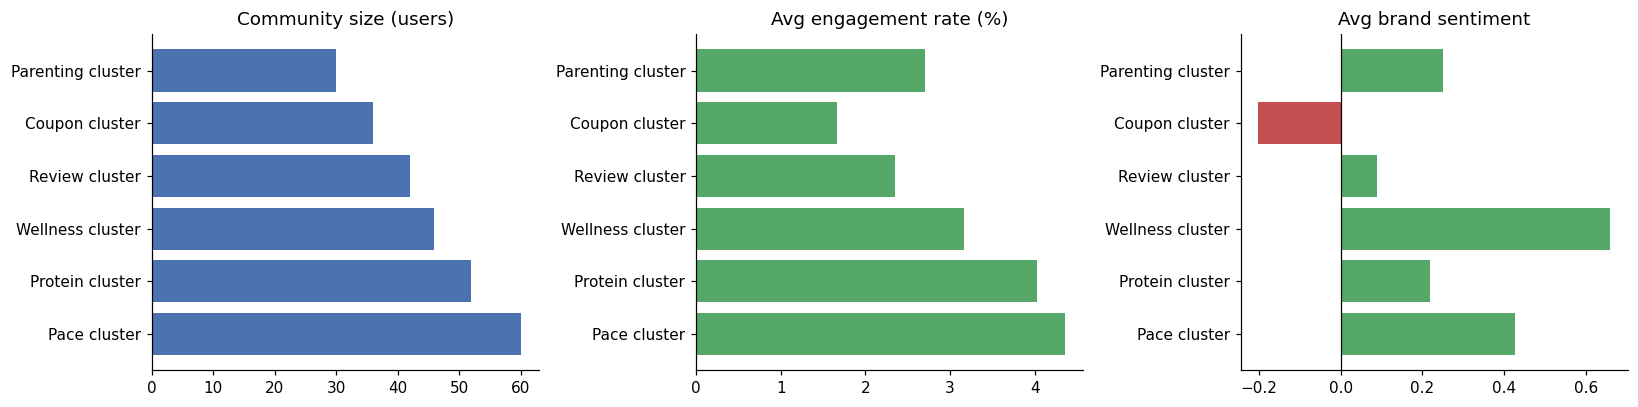

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
order = profile.sort_values("size", ascending=False)
ax[0].barh(order.label, order["size"], color="#4c72b0"); ax[0].set_title("Community size (users)")
ax[1].barh(order.label, order.avg_engagement_pct, color="#55a868"); ax[1].set_title("Avg engagement rate (%)")
ax[2].barh(order.label, order.avg_sentiment, color=["#c44e52" if s < 0 else "#55a868" for s in order.avg_sentiment])
ax[2].axvline(0, color="k", lw=0.8); ax[2].set_title("Avg brand sentiment")
plt.tight_layout(); plt.show()

## 10. Influencers and bridge users

* **Influencers:** highest weighted **PageRank** inside each community (central in the conversation, not merely high follower count).
* **Bridge users:** high **participation coefficient**: their interactions are spread across several communities, so they are natural carriers for cross-segment campaigns.

In [ ]:
users["pagerank"] = pd.Series(nx.pagerank(G, weight="weight"))

def participation(graph, node, label_of):
    k = graph.degree(node, weight="weight")
    if k == 0: return 0.0
    per = collections.Counter()
    for nb, d in graph[node].items():
        per[label_of[nb]] += d["weight"]
    return 1 - sum((v / k) ** 2 for v in per.values())

label_of = users.community.to_dict()
users["participation"] = [participation(G, n, label_of) for n in users.index]
users["degree"] = pd.Series(dict(G.degree()))

print("Top 3 influencers per community (by PageRank):")
infl = (users.sort_values("pagerank", ascending=False).groupby("segment").head(3)
        .sort_values(["segment", "pagerank"], ascending=[True, False])
        [["segment", "followers", "engagement_pct", "pagerank", "degree"]])
display(infl.round(4))

print("Top bridge users (cross-community connectors, degree >= 6):")
bridges = users[users.degree >= 6].sort_values("participation", ascending=False).head(8)
display(bridges[["segment", "degree", "participation", "followers"]].round(3))

Top 3 influencers per community (by PageRank):


,segment,followers,engagement_pct,pagerank,degree
user,,,,,
216,Coupon cluster,287,3.6741,0.0056,14
228,Coupon cluster,341,2.0035,0.0054,20
210,Coupon cluster,2088,0.8088,0.0050,18
36,Pace cluster,683,2.0315,0.0076,36
41,Pace cluster,321,4.3152,0.0053,26
22,Pace cluster,263,5.3594,0.0053,26
260,Parenting cluster,169,3.5727,0.0065,22
246,Parenting cluster,545,3.8693,0.0045,12
258,Parenting cluster,392,2.5129,0.0045,20


Top bridge users (cross-community connectors, degree >= 6):


,segment,degree,participation,followers
user,,,,
221,Coupon cluster,19,0.604,150
111,Protein cluster,17,0.566,238
188,Review cluster,12,0.528,42
194,Review cluster,15,0.519,769
234,Coupon cluster,13,0.515,74
257,Parenting cluster,16,0.508,953
181,Review cluster,17,0.491,989
166,Review cluster,17,0.483,802


## 11. From communities to marketing actions

In [ ]:
def recommend(row, med_eng):
    if row.avg_sentiment < 0:
        return "Win-back: address price/value concerns, offer bundles & limited-time deals"
    if row.avg_sentiment >= 0.4 and row.avg_engagement_pct >= med_eng:
        return "Advocates: referral programme, user-generated content, ambassador seeding"
    if row.avg_engagement_pct >= med_eng:
        return "Engaged: co-create content, product-feature education, early access"
    return "Awareness: low-effort educational content, partner with micro-influencers"

med_eng = profile.avg_engagement_pct.median()
plan = profile[["label", "size", "avg_sentiment", "avg_engagement_pct"]].copy()
plan["recommended_action"] = profile.apply(recommend, axis=1, med_eng=med_eng)
pd.set_option("display.max_colwidth", 100)
display(plan.sort_values("size", ascending=False).round(2).reset_index(drop=True))

,label,size,avg_sentiment,avg_engagement_pct,recommended_action
0,Pace cluster,60,0.43,4.36,"Advocates: referral programme, user-generated content, ambassador seeding"
1,Protein cluster,52,0.22,4.03,"Engaged: co-create content, product-feature education, early access"
2,Wellness cluster,46,0.66,3.17,"Advocates: referral programme, user-generated content, ambassador seeding"
3,Review cluster,42,0.09,2.35,"Awareness: low-effort educational content, partner with micro-influencers"
4,Coupon cluster,36,-0.20,1.66,"Win-back: address price/value concerns, offer bundles & limited-time deals"
5,Parenting cluster,30,0.25,2.71,"Awareness: low-effort educational content, partner with micro-influencers"


### Does community-aware seeding actually help?

We simulate information spread with the **Independent Cascade** model (each newly active user has one chance to activate each neighbour with probability *p*) and compare three seeding strategies with the same budget (one seed per community = 6 seeds):

1. **Community-aware:** top-PageRank user in every community
2. **Top-degree:** the 6 most-connected users overall
3. **Random:** 6 random users

We report average reach and the average number of communities in which at least 25% of users were activated.

,avg_users_reached,avg_communities_reached (>=25%)
Community-aware (PageRank / community),72.02,2.63
Top-degree overall,64.09,2.17
Random,60.63,2.06


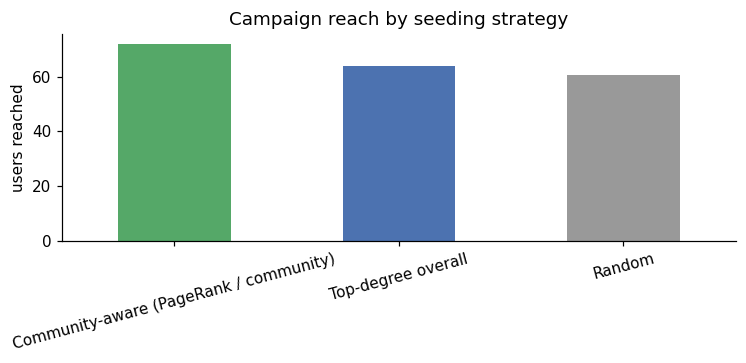

In [ ]:
adj = {n: [(m, G[n][m]["weight"]) for m in G[n]] for n in G}
wmax = max(w for nbrs in adj.values() for _, w in nbrs)

def independent_cascade(seeds, p=0.08, runs=300, seed=0):
    r = np.random.default_rng(seed)
    reach, covered = [], []
    comm_sizes = users.community.value_counts().to_dict()
    for _ in range(runs):
        active, frontier = set(seeds), list(seeds)
        while frontier:
            new = []
            for u in frontier:
                for v, w in adj[u]:
                    if v not in active and r.random() < min(1, p * (0.5 + w / wmax)):
                        active.add(v); new.append(v)
            frontier = new
        reach.append(len(active))
        cnt = users.loc[list(active), "community"].value_counts()
        covered.append(sum(cnt.get(c, 0) / s >= 0.25 for c, s in comm_sizes.items()))
    return np.mean(reach), np.mean(covered)

seeds_comm = users.sort_values("pagerank", ascending=False).groupby("community").head(1).index.tolist()
seeds_deg = users.sort_values("degree", ascending=False).head(len(seeds_comm)).index.tolist()

rand_res = [independent_cascade(rng.choice(nodes, len(seeds_comm), replace=False).tolist(), runs=60, seed=i) for i in range(10)]
results = pd.DataFrame({
    "Community-aware (PageRank / community)": independent_cascade(seeds_comm),
    "Top-degree overall": independent_cascade(seeds_deg),
    "Random": tuple(np.mean(rand_res, axis=0)),
}, index=["avg_users_reached", "avg_communities_reached (>=25%)"]).T
display(results.round(2))

results["avg_users_reached"].plot(kind="bar", rot=15, figsize=(7, 3.4), color=["#55a868", "#4c72b0", "#999999"])
plt.ylabel("users reached"); plt.title("Campaign reach by seeding strategy"); plt.tight_layout(); plt.show()

## 12. (Optional) Run on a real social network

The same pipeline works on any edge list. Below we load the **SNAP ego-Facebook** graph (4,039 users, ~88k friendships) and apply Louvain and Label Propagation. Real data has no ground truth, so we judge by **modularity** and community size distribution. Requires internet access in Colab.

> For your own business data, build `G` from a table of (user_a, user_b, interaction_count), e.g. mentions/retweets/replies exported from the X/Twitter, Reddit or Instagram APIs, with `nx.from_pandas_edgelist(df, "user_a", "user_b", edge_attr="weight")`.

In [ ]:
RUN_REAL_DATA = False     # set True to run
if RUN_REAL_DATA:
    import urllib.request, gzip, io
    url = "https://snap.stanford.edu/data/facebook_combined.txt.gz"
    raw = gzip.decompress(urllib.request.urlopen(url).read()).decode()
    RG = nx.read_edgelist(io.StringIO(raw), nodetype=int)
    print(RG)

    t0 = time.perf_counter()
    r_lou = nx.community.louvain_communities(RG, seed=SEED)
    print(f"Louvain: {len(r_lou)} communities, Q = {nx.community.modularity(RG, r_lou):.3f}, {time.perf_counter()-t0:.1f}s")

    t0 = time.perf_counter()
    r_lpa = list(nx.community.asyn_lpa_communities(RG, seed=SEED))
    print(f"Label Propagation: {len(r_lpa)} communities, Q = {nx.community.modularity(RG, r_lpa):.3f}, {time.perf_counter()-t0:.1f}s")

    # CPM is expensive on dense ego-networks; use a large k (and be patient)
    t0 = time.perf_counter()
    r_cpm = [set(c) for c in nx.community.k_clique_communities(RG, 10)]
    print(f"CPM k=10: {len(r_cpm)} communities covering {len(set().union(*r_cpm)) if r_cpm else 0} users, {time.perf_counter()-t0:.1f}s")

    sizes_r = sorted((len(c) for c in r_lou), reverse=True)
    plt.figure(figsize=(6, 3)); plt.bar(range(len(sizes_r)), sizes_r)
    plt.title("Louvain community sizes (SNAP Facebook)"); plt.xlabel("community rank"); plt.ylabel("users"); plt.show()

## 13. Conclusions

* **Louvain** gave a full, non-overlapping segmentation that recovered all 6 planted segments (NMI = 1.0) in milliseconds. It scales to millions of edges and is the best default for audience segmentation. Tune `resolution` to control granularity.
* **Label Propagation** matched Louvain on this clean, well-separated network, but it is non-deterministic and typically less stable on noisier real graphs, so re-run with several seeds before trusting it.
* **Clique Percolation** is the only method here that surfaces **overlapping** membership (it flagged most of the planted bridge users), but on this graph it fragmented segments into many small communities, left ~15% of users uncovered, and was very sensitive to *k* (k=3 merges everything, k>=5 covers few users). Use it as a complement for finding cross-over audiences, not as the primary segmentation.
* **Business value:** communities turned into named segments with sentiment/engagement profiles, per-community influencers, bridge users for cross-promotion, and an action plan; in the cascade simulation, seeding one influencer per community reached more users and more segments than top-degree or random seeding (results depend on the spread probability *p* and the random seed).

**Limitations / next steps:** real graphs are directed and temporal (try Leiden, Infomap, or dynamic community detection); add text embeddings of posts to combine content and structure; validate segments through A/B-tested campaigns; respect platform ToS and user privacy when collecting data.